# Incendios en España: EDA

## 0. Comprobación

### Comienzo importando las librerías que necesitaré. Pandas para trabajar las tablas, matplotlib para hacer gráficas y datetime para las fechas.

In [2]:
import pandas as pd
import matplotlib
import datetime 

print("Todo listo")

Todo listo


## 1. ¿Que tengo?

### Leo mi tabla con read_csv y comprobamos que funciona.

In [3]:
incendios = pd.read_csv("datos/incendios.csv")

incendios.head(5)

,id,superficie,fecha,lat,lng,latlng_explicit,idcomunidad,idprovincia,idmunicipio,municipio,...,causa_supuesta,causa_desc,muertos,heridos,time_ctrl,time_ext,personal,medios,gastos,perdidas
0,1968290001,14.0,1968-01-01,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,40,0,0,NaN,360.0,0,0,0.0,0.0
1,1968430003,3.0,1968-01-03,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,0,0,0,NaN,60.0,0,0,0.0,0.0
2,1968290006,2.0,1968-01-06,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,0,0,0,NaN,120.0,0,0,0.0,0.0
3,1968120007,8.2,1968-01-07,NaN,NaN,NaN,9,12,0,INDETERMINADO,...,1,20,0,0,NaN,120.0,0,0,0.0,0.0
4,1968430016,600.0,1968-01-07,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,20,0,0,NaN,1440.0,35,1,0.0,0.0


### A continuación, compruebo los datos que nos interesan de la tabla. La cantidad de columnas y filas con .shape, o el tipo de columnas con .info()

In [4]:
incendios.shape

(296839, 21)

In [5]:
incendios.info()

<class 'pandas.DataFrame'>
RangeIndex: 296839 entries, 0 to 296838
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               296839 non-null  int64  
 1   superficie       296839 non-null  float64
 2   fecha            296839 non-null  str    
 3   lat              242439 non-null  float64
 4   lng              242439 non-null  float64
 5   latlng_explicit  242446 non-null  float64
 6   idcomunidad      296839 non-null  int64  
 7   idprovincia      296839 non-null  int64  
 8   idmunicipio      296839 non-null  int64  
 9   municipio        296839 non-null  str    
 10  causa            296839 non-null  int64  
 11  causa_supuesta   296839 non-null  int64  
 12  causa_desc       296839 non-null  int64  
 13  muertos          296839 non-null  int64  
 14  heridos          296839 non-null  int64  
 15  time_ctrl        143055 non-null  float64
 16  time_ext         296838 non-null  float64
 17  pe

### Hay 296839 filas y 21 columnas. Hay dos columnas de texto, el resto son numéricas, ya sean integrales o float. A continuación elimino las columnas que de entrada no utilizaré, y las renombro a mi gusto.

In [6]:
incendios = incendios[["superficie", "fecha", "lat", "lng", "latlng_explicit", "idcomunidad", "idprovincia", "municipio", "causa", "causa_supuesta", "muertos", "heridos", "time_ctrl", "time_ext", "personal", "medios", "gastos", "perdidas"]]

In [7]:
incendios.columns = ["hectareas", "fecha", "latitud", "longitud", "ubicación exacta", "comunidad", "provincia", "municipio", "causa", "confirmacion causa", "muertos", "heridos", "tiempo de control", "tiempo de extincion", "personal", "medios", "gastos", "perdidas"]

incendios.head(5)       

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de control,tiempo de extincion,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,4,29,INDETERMINADO,2,1,0,0,NaN,360.0,0,0,0.0,0.0
1,3.0,1968-01-03,NaN,NaN,NaN,2,43,INDETERMINADO,5,1,0,0,NaN,60.0,0,0,0.0,0.0
2,2.0,1968-01-06,NaN,NaN,NaN,4,29,INDETERMINADO,5,1,0,0,NaN,120.0,0,0,0.0,0.0
3,8.2,1968-01-07,NaN,NaN,NaN,9,12,INDETERMINADO,3,1,0,0,NaN,120.0,0,0,0.0,0.0
4,600.0,1968-01-07,NaN,NaN,NaN,2,43,INDETERMINADO,3,1,0,0,NaN,1440.0,35,1,0.0,0.0


## 2. ¿Que me falta?

### Tras eliminar las columnas que no quiero y renombrar el resto, es el momento de comprobar huecos con isna().sum()

In [8]:
incendios.isna().sum()

hectareas                   0
fecha                       0
latitud                 54400
longitud                54400
ubicación exacta        54393
comunidad                   0
provincia                   0
municipio                   0
causa                       0
confirmacion causa          0
muertos                     0
heridos                     0
tiempo de control      153784
tiempo de extincion         1
personal                    0
medios                      0
gastos                      0
perdidas                    0
dtype: int64

In [9]:
round(incendios.isna().sum() / len(incendios) * 100 , 1)

hectareas               0.0
fecha                   0.0
latitud                18.3
longitud               18.3
ubicación exacta       18.3
comunidad               0.0
provincia               0.0
municipio               0.0
causa                   0.0
confirmacion causa      0.0
muertos                 0.0
heridos                 0.0
tiempo de control      51.8
tiempo de extincion     0.0
personal                0.0
medios                  0.0
gastos                  0.0
perdidas                0.0
dtype: float64

### Faltan el 18.3 % de datos en latitud, longitud y ubicación exacta. Son los incendios anteriores a los 80, sin los datos de ubicación. Por otra parte faltan el 51.8 % de datos de tiempo de control y 1 hueco de tiempo de extinción

In [10]:
incendios = incendios.dropna(subset=["latitud", "longitud", "ubicación exacta"])

incendios.shape

(242439, 18)

### Elimino todas las filas sin latitud, longitud y ubicación exacta, ya que me darían problemas a la hora de hacer el mapa. Además, esas filas tienen muchos valores a 0, aunque no sean nulos probablemente haya mucha falta de registros en incendios antiguos.

In [11]:
print("Tiempo de control de incendios: Mediana", incendios["tiempo de control"].median() , "Media", incendios["tiempo de control"].mean().round(1) )



Tiempo de control de incendios: Mediana 140.0 Media 290.6


In [12]:
incendios = incendios.drop(columns = "tiempo de control")  # Esta columna es interesante pero es demasiado incompleta, y para medir el tiempo tenemos la columna de tiempo de extinción



### La diferencia entre la media y la mediana del tiempo de control es demasiado grande cómo para llenar los huecos con la mediana, así que elimino la columna entera.

In [13]:
incendios = incendios.dropna(subset =["tiempo de extincion"])

### Finalmente elimino la fila con hueco en tiempo de extinción y compruebo que no queden huecos.

In [14]:
incendios.isna().sum()

hectareas              0
fecha                  0
latitud                0
longitud               0
ubicación exacta       0
comunidad              0
provincia              0
municipio              0
causa                  0
confirmacion causa     0
muertos                0
heridos                0
tiempo de extincion    0
personal               0
medios                 0
gastos                 0
perdidas               0
dtype: int64

## 3. Filas repetidas

### Ya he eliminado los huecos, a continuación voy a buscar posibles duplicados. 

In [15]:
print("Filas repetidas", incendios.duplicated().sum())

Filas repetidas 25


In [16]:
incendios[incendios.duplicated()].head(25)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
171753,1.60,1998-07-05,41.432321,1.266931,1.0,2,43,BARBERÀ DE LA CONCA,2,1,0,0,143.0,18,5,0.0,0.0
172338,10.00,1998-07-31,40.023320,-5.769695,1.0,14,10,TORREMENGA,4,1,0,0,135.0,43,5,0.0,0.0
177576,1.00,1999-02-07,41.921828,-7.303261,1.0,3,32,VILARDEVÓS,4,0,0,0,45.0,4,1,0.0,0.0
179427,1.00,1999-04-05,39.355808,-5.084769,1.0,14,6,CASTILBLANCO,2,0,0,0,120.0,5,1,0.0,1376.0
179428,1.00,1999-04-05,39.355808,-5.084769,1.0,14,6,CASTILBLANCO,2,0,0,0,120.0,5,1,0.0,1376.0
179534,10.00,1999-04-07,38.482152,-5.673496,1.0,14,6,PERALEDA DEL ZAUCEJO,2,0,0,0,250.0,11,3,0.0,0.0
186444,1.30,2000-03-20,42.218250,-7.369252,1.0,3,32,CHANDREXA DE QUEIXA,4,1,0,0,125.0,5,0,0.0,0.0
189651,1.00,2000-08-29,42.286665,-7.163543,1.0,3,32,MANZANEDA,4,1,0,0,34.0,5,0,0.0,0.0
199193,1.80,2001-12-21,42.052345,-7.907894,1.0,3,32,BANDE,4,1,0,0,210.0,9,1,0.0,0.0
213546,1.00,2003-09-20,42.217695,-7.201441,1.0,3,32,VILARIÑO DE CONSO,4,1,0,0,75.0,11,1,0.0,0.0


In [17]:
incendios = incendios.drop(index = 179427)   

### Tras comprobar los duplicados, veo que el incendio de Castilblanco es, seguramente, un duplicado, así que lo elimino.

## 4. ¿Cómo son los números?

### Con describe() compruebo cómo son los datos que tengo.

In [18]:
incendios.describe()

,hectareas,latitud,longitud,ubicación exacta,comunidad,provincia,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
count,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,2.424370e+05,2.424370e+05
mean,24.292923,41.686413,-5.722239,0.372988,7.505496,27.864818,3.866394,0.772861,0.000751,0.007631,524.183483,22.567030,2.520090,8.175266e+02,1.051647e+04
std,263.708775,1.952367,2.549794,0.483600,5.483804,11.740228,1.028980,0.418984,0.062594,0.182016,1692.451383,45.636149,5.728802,1.644875e+04,2.697969e+05
min,1.000000,27.707179,-18.148781,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,-1352.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,1.500000,40.853846,-7.520661,0.000000,3.000000,19.000000,4.000000,1.000000,0.000000,0.000000,135.000000,6.000000,0.000000,0.000000e+00,0.000000e+00
50%,3.000000,42.340465,-6.285200,0.000000,5.000000,32.000000,4.000000,1.000000,0.000000,0.000000,240.000000,12.000000,1.000000,0.000000e+00,0.000000e+00
75%,9.000000,43.060419,-4.382002,1.000000,13.000000,36.000000,4.000000,1.000000,0.000000,0.000000,448.000000,25.000000,3.000000,0.000000e+00,6.010000e+02
max,29867.000000,43.765502,4.274832,1.000000,18.000000,51.000000,6.000000,1.000000,20.000000,30.000000,230370.000000,3612.000000,438.000000,2.793745e+06,5.484489e+07


### Varias cosas me han llamado la atención, así que he ido comprobándolas.

### Efectivamente, el mayor incendio hasta la fecha de estos datos coincide con mi máximo. El máximo tiempo de extinción me parecía desproporcionado pasando los 5 meses. Tras investigar, vi que un incendio se considera extinguido cuando no hay ningún riesgo de que se reactive. Por lo tanto, 5 meses de tiempo de extinción es un valor posible si hablamos de algún gran incendio.

In [19]:
print("Hectáreas quemadas: Mediana", int(incendios["hectareas"].median()) , "Media", int(incendios["hectareas"].mean()) )

Hectáreas quemadas: Mediana 3 Media 24


<Axes: title={'center': 'Hectáreas quemadas'}, ylabel='Frequency'>

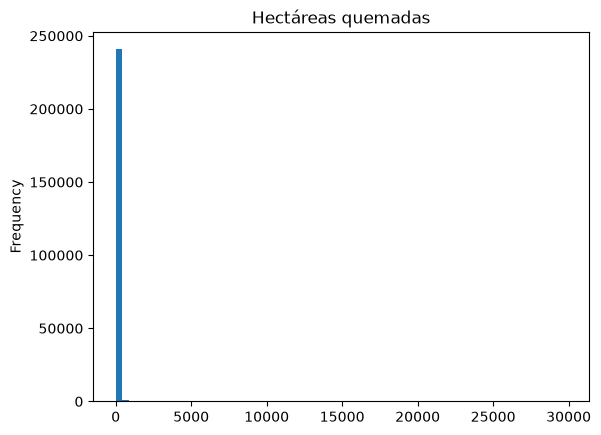

In [20]:
incendios["hectareas"].plot(kind= "hist", bins = 70, title = "Hectáreas quemadas")  

### Viendo la mediana, la media y el histograma de las hectáreas quemadas, podemos ver que hay muchos incendios muy pequeños, que mantienen la mediana en 3.

## 5. ¿Hay algo raro?

In [21]:
incendios.sort_values("hectareas", ascending = False).head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
218907,29867.0,2004-07-27,37.691760,-6.599990,1.0,4,21,MINAS DE RIOTINTO,4,0,0,1,11065.0,1504,123,0.0,4488390.0
263245,28879.1,2012-06-28,39.269115,-0.955787,1.0,9,46,CORTES DE PALLÁS,3,0,1,0,24772.0,540,146,0.0,12607966.0
139510,28213.3,1994-07-02,40.637450,-0.527527,0.0,10,44,VILLARLUENGO,1,1,0,0,8790.0,1063,64,95861.0,23637217.0
139555,25579.0,1994-07-04,38.568266,-1.727008,0.0,11,2,HELLÍN,2,1,0,0,7200.0,936,137,974753.0,2317275.0
139623,25430.0,1994-07-04,39.224837,-0.845232,0.0,9,46,MILLARES,1,1,9,0,11910.0,423,34,0.0,6350780.0


In [22]:
incendios.sort_values("hectareas", ascending = True).head(5) 

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
296809,1.0,2022-12-31,43.330568,-5.652539,1.0,5,33,LANGREO,4,1,0,0,172.0,3,2,0.0,0.0
296786,1.0,2022-12-21,43.320291,-5.425302,1.0,5,33,PILOÑA,4,1,0,0,4501.0,3,2,0.0,0.0
54453,1.0,1983-01-22,42.329642,-7.332653,0.0,3,32,"POBRA DE TRIVES, A",4,1,0,0,900.0,5,0,0.0,0.0
296757,1.0,2022-11-07,43.445497,-5.049705,1.0,5,33,RIBADESELLA,4,1,0,0,1038.0,3,2,0.0,0.0
214298,1.0,2004-02-06,43.050841,-6.702613,0.0,5,33,CANGAS DEL NARCEA,2,1,0,0,90.0,2,0,0.0,0.0


<Axes: title={'center': 'Hectareas quemadas'}>

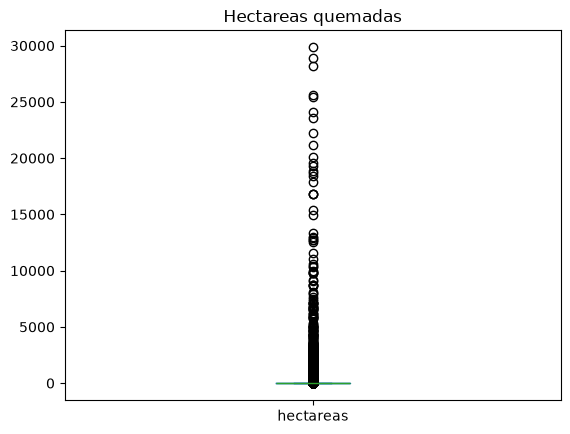

In [23]:
incendios["hectareas"].plot(kind= "box", title = "Hectareas quemadas")

### Compruebo valores de hectareas y hago también el diagrama de caja, comprobando de nuevo la alta cantidad de pequeños incendios. 

In [24]:
print("Filas vacías en gasto:", round(len(incendios[incendios["gastos"] == 0]) / len(incendios) * 100, 1), "%. Filas vacás en perdidas:", round(len(incendios[incendios["perdidas"] == 0]) / len(incendios) * 100, 1), "%" )

Filas vacías en gasto: 81.0 %. Filas vacás en perdidas: 57.0 %


### Gasto y pérdidas tienen ambas una alta cantidad de 0. Sabiendo que muchos incendios son muy pequeños, puede que efectivamente, no hayan pérdidas ni gastos. Pero también es probable que esto se deba a que el dato no esté registrado. De hecho, en el indendio de Minas de Riotinto, el más grande, el valor de los gastos es de 0, no tiene sentido. 

### Al faltar tantos datos en ambas columnas, no serían útiles a la hora de buscar relación entre ellas y otras columnas. Sin embargo, creo que son datos interesantes para al menos, mostrarlos en la app final. Mi idea es crear un segundo csv al acabar el EDA, con los incendios con alto impacto económico, para poder mostrarlos.

### A continuación, antes de analizar los datos y comenzar a sacar conclusiones, quiero hacer varias modificaciones en la tabla. Para empezar, no quiero que las columnas de comunidad, provincia y causa sean códigos numéricos, prefiero ver los nombres de cada comunidad, provincia y causa.

In [25]:
incendios["comunidad"] = incendios["comunidad"].replace({
    1: "País Vasco",
    2: "Cataluña",
    3: "Galicia",
    4: "Andalucía",
    5: "Asturias",
    6: "Cantabria",
    7: "La Rioja",
    8: "Murcia",
    9: "Comunidad Valenciana",
    10: "Aragón",
    11: "Castilla-La Mancha",
    12: "Islas Canarias",
    13: "Navarra",
    14: "Extremadura",
    15: "Islas Baleares",
    16: "Madrid",
    17: "Castilla y León",
    18: "Ceuta y Melilla"
    
})

incendios.head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,42.376191,-7.004868,0.0,Galicia,32,"BARCO DE VALDEORRAS, O",4,1,0,0,420.0,12,0,0.0,1.0
54383,2.0,1983-01-04,38.942962,-0.361213,0.0,Comunidad Valenciana,46,LUTXENT,5,1,0,0,180.0,13,0,0.0,0.0
54384,15.0,1983-01-05,40.133460,-0.686263,0.0,Aragón,44,RUBIELOS DE MORA,2,1,0,0,360.0,78,0,1.0,0.0
54385,15.0,1983-01-05,39.302764,-0.777780,0.0,Comunidad Valenciana,46,DOS AGUAS,5,1,0,0,300.0,63,1,0.0,2.0
54386,95.0,1983-01-06,40.242209,-0.056820,0.0,Comunidad Valenciana,12,SIERRA ENGARCERÁN,4,1,0,0,1440.0,22,0,0.0,0.0


### Con replace y un diccionario cambo cada número en la columna de comunidad por el nombre correspondiente, de esta forma es mucho más visual. Hago lo mismo con la provincia y la causa. Las correspondencias de los códigos se pueden buscar en Internet.

In [26]:
incendios["provincia"] = incendios["provincia"].replace({
    1: "Álava",
    2: "Albacete",
    3: "Alicante",
    4: "Almería",
    5: "Ávila",
    6: "Badajoz",
    7: "Islas Baleares",
    8: "Barcelona",
    9: "Burgos",
    10: "Cáceres",
    11: "Cádiz",
    12: "Castellón",
    13: "Ciudad Real",
    14: "Córdoba",
    15: "A Coruña",
    16: "Cuenca",
    17: "Girona",
    18: "Granada",
    19: "Guadalajara",
    20: "Gipuzkoa",
    21: "Huelva",
    22: "Huesca",
    23: "Jaén",
    24: "León",
    25: "Lleida",
    26: "La Rioja",
    27: "Lugo",
    28: "Madrid",
    29: "Málaga",
    30: "Murcia",
    31: "Navarra",
    32: "Ourense",
    33: "Asturias",
    34: "Palencia",
    35: "Las Palmas",
    36: "Pontevedra",
    37: "Salamanca",
    38: "Santa Cruz de Tenerife",
    39: "Cantabria",
    40: "Segovia",
    41: "Sevilla",
    42: "Soria",
    43: "Tarragona",
    44: "Teruel",
    45: "Toledo",
    46: "Valencia",
    47: "Valladolid",
    48: "Bizkaia",
    49: "Zamora",
    50: "Zaragoza",
    51: "Ceuta",
    52: "Melilla"
})


incendios.tail(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
296838,1.8,2023-12-08,37.608123,-1.012078,1.0,Murcia,Murcia,CARTAGENA,4,0,0,0,138.0,10,2,0.0,0.0


In [27]:
incendios["causa"] = incendios["causa"].replace({
    1: "Causa Natural",
    2: "Negligencias y accidentes",
    3: "Intencionados",
    4: "Causa desconocida",
    5: "Reproducciones",
    6: "Otras causas humanas"
})

incendios.head(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,42.376191,-7.004868,0.0,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,1,0,0,420.0,12,0,0.0,1.0


### Tras comprobar que funciona, voy con la ubicación exacta y la confirmación de la causa. 

In [28]:
incendios["ubicación exacta"] = incendios["ubicación exacta"].replace({
    1: "Si",
    0: "Municipio más cercano"
})

In [29]:
incendios["confirmacion causa"] = incendios["confirmacion causa"].replace({
    1: "Supuesta",
    0: "Confirmada"
})

incendios.head(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0


### Compruebo que los cambios funcionan A continuación, es el momento de crear las columnas año y mes para poder analizar y mostrar mejor cuando ocurren los incendios.

In [30]:
incendios.insert(2, "año", pd.to_datetime(incendios["fecha"]).dt.year)

incendios.head(1)

,hectareas,fecha,año,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,1980,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0


In [31]:
incendios.insert(3, "mes", pd.to_datetime(incendios["fecha"]).dt.month)

incendios.head(1)

,hectareas,fecha,año,mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,1980,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0


In [32]:
incendios.insert(4, "numero mes", pd.to_datetime(incendios["fecha"]).dt.month)

incendios.head(1)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,1980,9,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0


### Con .insert() creo las dos columnas, decido su posición para que estén al lado de fecha y utilizando to_datetime le doy a cada fila los valores de año y mes correspondiente. A continuación, cambio los números de los meses por sus nombres, igual que con las comunidades, provincias, etc.

In [33]:
incendios["mes"] = incendios["mes"].replace({
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
})

incendios.head(2)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
39711,20.0,1980-09-18,1980,Septiembre,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0
54383,2.0,1983-01-04,1983,Enero,1,38.942962,-0.361213,Municipio más cercano,Comunidad Valenciana,Valencia,LUTXENT,Reproducciones,Supuesta,0,0,180.0,13,0,0.0,0.0


### Finalmente, me interesa sumar las columnas de gastos y perdidas para ver el impacto economico total, aunque no tenga la información de la mayoría de incendios.

In [34]:
incendios["impacto economico"] = incendios ["gastos"] + incendios ["perdidas"]

incendios.head(1)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,...,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas,impacto economico
39711,20.0,1980-09-18,1980,Septiembre,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,...,Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0,1.0


## 6. ¿Que hay más?

### Ahora por fin tengo la tabla cómo la quiero. Es el momento de analizar los datos y comenzar a sacar conclusiones. Para empezar, el número de incendios por comunidades, el porcentaje y el gráfico de barras.

In [35]:
incendios["comunidad"].value_counts()

comunidad
Galicia                 82578
Castilla y León         39754
Asturias                30853
Andalucía               17982
Extremadura             16735
Cantabria               14969
Castilla-La Mancha       9498
Cataluña                 6379
Comunidad Valenciana     5956
Aragón                   4016
Navarra                  3482
País Vasco               3425
Madrid                   2871
La Rioja                 1317
Islas Baleares            937
Murcia                    867
Islas Canarias            800
Ceuta y Melilla            18
Name: count, dtype: int64

In [36]:
round(incendios["comunidad"].value_counts() / len(incendios) * 100, 1)

comunidad
Galicia                 34.1
Castilla y León         16.4
Asturias                12.7
Andalucía                7.4
Extremadura              6.9
Cantabria                6.2
Castilla-La Mancha       3.9
Cataluña                 2.6
Comunidad Valenciana     2.5
Aragón                   1.7
Navarra                  1.4
País Vasco               1.4
Madrid                   1.2
La Rioja                 0.5
Islas Baleares           0.4
Murcia                   0.4
Islas Canarias           0.3
Ceuta y Melilla          0.0
Name: count, dtype: float64

<Axes: ylabel='comunidad'>

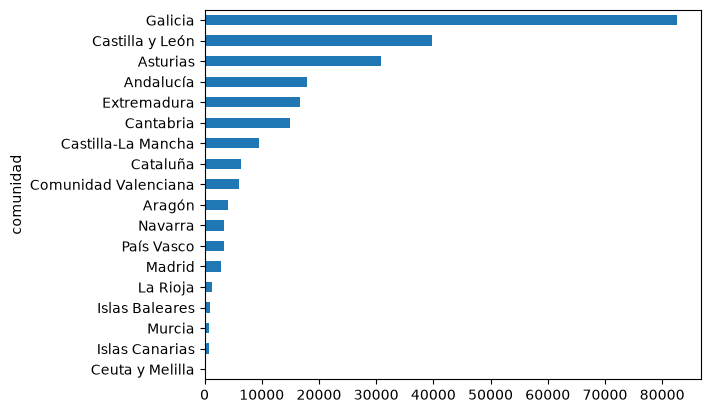

In [37]:
incendios["comunidad"].value_counts(ascending = True).plot(kind = "barh")

### Haciendo el value_counts() por provincia se puede observar diferencias entre y dentro de las comunidades. Castilla y León es la segunda comunidad con más incendios, sin embargo, al tener 9 provincias, el número de incendios está repartido. Lo contrario pasa con Asturias o Cantabria, que son comunidades de una sola provincia. 

In [38]:
incendios["provincia"].value_counts().head(10)

provincia
Ourense       32627
Asturias      30853
Pontevedra    17862
A Coruña      17241
León          15381
Cantabria     14969
Lugo          14848
Cáceres       10706
Zamora        10276
Badajoz        6029
Name: count, dtype: int64

### A continuación, porcentaje de las causas.

In [39]:
round(incendios["causa"].value_counts() / len(incendios) * 100, 1)

causa
Causa desconocida            55.2
Reproducciones               23.9
Negligencias y accidentes    14.3
Intencionados                 3.6
Causa Natural                 2.2
Otras causas humanas          0.8
Name: count, dtype: float64

In [40]:
round(incendios["confirmacion causa"].value_counts() / len(incendios) * 100, 1)

confirmacion causa
Supuesta      77.3
Confirmada    22.7
Name: count, dtype: float64

### Vemos que en las causas también hay muchos datos que no son demasiado claros. Ante la pregunta de cuantos incendios son provocados por humanos, hay varias dudas. Por una parte, sólo el 22.7 por ciento de las causas están confirmadas, el resto son supuestos. Además, en ese 22.7%, el 55.2 son de causa desconocida, mientras que el 23.9 son reproducciones, es decir, son originados a raíz de otro incendio, por lo cual la causa original es otra. 


In [41]:
causas_confirmadas = incendios[incendios["confirmacion causa"] == "Confirmada"]

causas_conocidas = causas_confirmadas[(causas_confirmadas["causa"] != "Causa desconocida") & (causas_confirmadas["causa"] != "Reproducciones")]

round(causas_conocidas["causa"].value_counts() / len(causas_conocidas) * 100, 1)

causa
Negligencias y accidentes    53.8
Intencionados                26.8
Causa Natural                12.7
Otras causas humanas          6.7
Name: count, dtype: float64

In [42]:
print("Conocemos la causa confirmada de", len(causas_conocidas), "incendios")

Conocemos la causa confirmada de 19032 incendios


### Aquí saco los porcentajes de las causas confirmadas, excluyendo las causas desconocidas y las reproducciones. Es decir, los porcentajes de las causas originales confirmadas. Hay que aclarar que es un porcentaje bajo del total de incendios, pero 19032 pueden ser una buena muestra.

### Vamos con los meses.

In [43]:
incendios["mes"].value_counts()

mes
Agosto        44752
Septiembre    37372
Marzo         36718
Julio         27770
Febrero       21804
Abril         18902
Octubre       14720
Junio         13224
Mayo           9284
Enero          8073
Diciembre      5841
Noviembre      3977
Name: count, dtype: int64

In [44]:
round(incendios["mes"].value_counts(normalize = True) * 100, 1)

mes
Agosto        18.5
Septiembre    15.4
Marzo         15.1
Julio         11.5
Febrero        9.0
Abril          7.8
Octubre        6.1
Junio          5.5
Mayo           3.8
Enero          3.3
Diciembre      2.4
Noviembre      1.6
Name: proportion, dtype: float64

<Axes: ylabel='mes'>

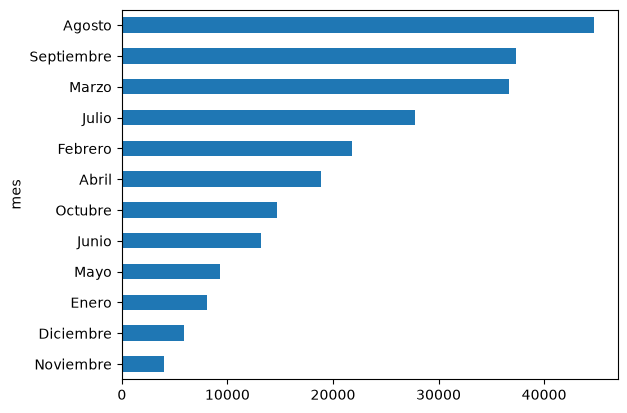

In [45]:
incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

### El mes con más incendios es Agosto, cómo esperaba. Sin embargo, no esperaba ver Marzo y Febrero tan altos, y me sorprende también que Junio esté bastante bajo.

In [46]:
incendios["año"].value_counts(ascending = False)

año
1989    15922
1995    10145
1985    10119
2000     9340
2005     9010
1990     8413
1994     8274
1997     8179
1998     7939
2002     7813
2004     7643
1991     7450
1992     7336
2001     6921
1988     6743
2003     6622
1999     6486
1987     6454
1996     5775
2009     5772
1986     5665
1984     5614
2011     5595
2006     5590
2012     5530
2017     5223
1993     4983
2008     4352
2015     4121
2010     3906
2019     3828
2007     3408
1983     3403
2014     3194
2013     3083
2021     2897
2020     2700
2022     2520
2016     2432
2018     2013
2023       23
1980        1
Name: count, dtype: int64

<Axes: xlabel='año'>

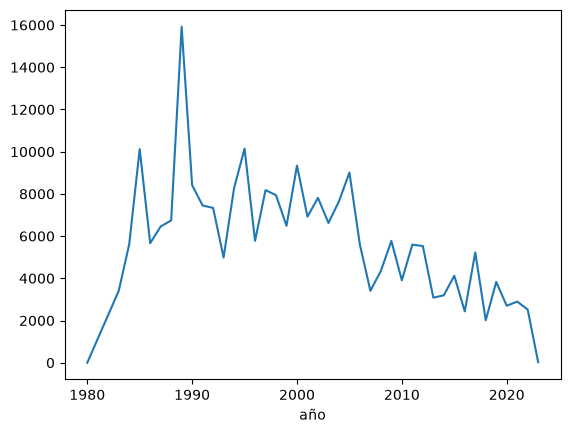

In [47]:
incendios["año"].value_counts().sort_index().plot(kind = "line")

### Haciendo value_counts() con los años y haciendo la gráfica, se puede observar que en los últimos se ha ido reduciendo el número de incendios.

## 7. ¿Cambia algo de un grupo a otro?

### Es el momento de encontrar relaciones entre columnas. Primero, voy a desglosar el porcentaje de incendios por provincia en cada comunidad.

In [48]:
round(incendios.groupby("comunidad")["provincia"].value_counts(normalize = True) * 100, 1)

comunidad             provincia             
Andalucía             Huelva                     21.3
                      Málaga                     17.1
                      Sevilla                    11.5
                      Jaén                       11.3
                      Cádiz                      11.1
                      Granada                    10.3
                      Córdoba                     9.9
                      Almería                     7.5
Aragón                Zaragoza                   44.8
                      Huesca                     35.3
                      Teruel                     19.9
Asturias              Asturias                  100.0
Cantabria             Cantabria                 100.0
Castilla y León       León                       38.7
                      Zamora                     25.8
                      Salamanca                   8.9
                      Burgos                      8.5
                      Ávila          

### A continuación voy a observar varios datos que me pueden interesar utilizando .groupby

In [49]:
incendios.groupby("comunidad")["hectareas"].sum().sort_values(ascending = False)

comunidad
Galicia                 1.299928e+06
Castilla y León         1.201839e+06
Andalucía               6.148079e+05
Comunidad Valenciana    5.134446e+05
Extremadura             4.976047e+05
Asturias                4.293535e+05
Cataluña                3.132533e+05
Castilla-La Mancha      3.125683e+05
Cantabria               2.332663e+05
Aragón                  1.824707e+05
Islas Canarias          1.145171e+05
Madrid                  4.653641e+04
País Vasco              3.734570e+04
Navarra                 3.704043e+04
Islas Baleares          2.738037e+04
La Rioja                1.614657e+04
Murcia                  1.156651e+04
Ceuta y Melilla         4.345400e+02
Name: hectareas, dtype: float64

In [50]:
incendios.groupby("año")["hectareas"].sum()

año
1980        20.0000
1983    107151.9000
1984    163755.2000
1985    483843.7000
1986    264276.9000
1987    146692.3000
1988    136607.7000
1989    405892.2000
1990    202489.7000
1991    258953.4000
1992    103348.1000
1993     87424.1000
1994    435181.4000
1995    137608.3200
1996     56718.1600
1997     95538.9900
1998    130024.8900
1999     79486.7900
2000    184577.1500
2001     89797.6200
2002    104701.8800
2003    145648.1500
2004    131212.5800
2005    185154.5700
2006    153118.9500
2007     84667.9300
2008     48629.2000
2009    117934.8500
2010     53175.3200
2011     99614.7000
2012    216496.9500
2013     60044.3300
2014     47154.8700
2015    107796.8700
2016     67971.4800
2017    181649.7512
2018     25951.8757
2019     85079.1705
2020     70243.4206
2021     91378.3686
2022    242436.1565
2023        53.4300
Name: hectareas, dtype: float64

In [51]:
incendios.groupby("año")["hectareas"].sum().sort_values(ascending = False)

año
1985    483843.7000
1994    435181.4000
1989    405892.2000
1986    264276.9000
1991    258953.4000
2022    242436.1565
2012    216496.9500
1990    202489.7000
2005    185154.5700
2000    184577.1500
2017    181649.7512
1984    163755.2000
2006    153118.9500
1987    146692.3000
2003    145648.1500
1995    137608.3200
1988    136607.7000
2004    131212.5800
1998    130024.8900
2009    117934.8500
2015    107796.8700
1983    107151.9000
2002    104701.8800
1992    103348.1000
2011     99614.7000
1997     95538.9900
2021     91378.3686
2001     89797.6200
1993     87424.1000
2019     85079.1705
2007     84667.9300
1999     79486.7900
2020     70243.4206
2016     67971.4800
2013     60044.3300
1996     56718.1600
2010     53175.3200
2008     48629.2000
2014     47154.8700
2018     25951.8757
2023        53.4300
1980        20.0000
Name: hectareas, dtype: float64

<Axes: xlabel='año'>

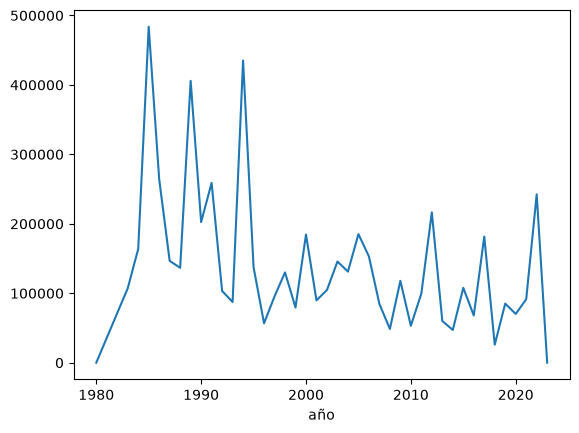

In [52]:
incendios.groupby("año")["hectareas"].sum().plot(kind = "line")

In [53]:
incendios.groupby(["mes"])["hectareas"].sum().sort_values(ascending = False)

mes
Agosto        1.633105e+06
Julio         1.396002e+06
Septiembre    8.808410e+05
Marzo         4.320942e+05
Junio         3.344039e+05
Octubre       3.125587e+05
Febrero       2.826924e+05
Abril         2.391747e+05
Diciembre     1.228750e+05
Mayo          1.059807e+05
Enero         1.024145e+05
Noviembre     4.736060e+04
Name: hectareas, dtype: float64

<Axes: ylabel='mes'>

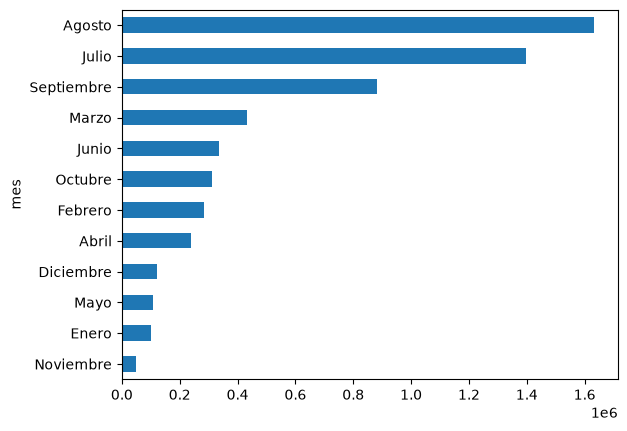

In [54]:
incendios.groupby(["mes"])["hectareas"].sum().sort_values().plot(kind = "barh")

### En esta tabla se observa la cantidad de hectáreas que se quema en cada mes, y se puede apreciar una diferencia respecto al número de incendios. Las hectáreas afectadas se concentran más en los meses de verano más calurosos, mientras que en el número de incendios vemos otros meses más fríos muy arriba.

<Axes: xlabel='mes'>

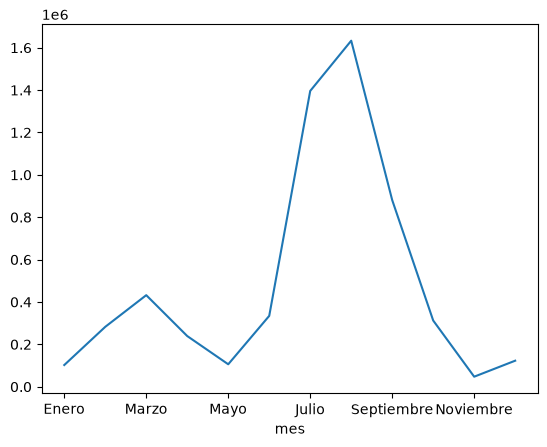

In [55]:
incendios.groupby(["numero mes", "mes"])["hectareas"].sum().sort_index().droplevel(0).plot(kind="line")

In [56]:
incendios.groupby("año")["muertos"].sum()

año
1980     0
1983    10
1984    20
1985     4
1986     0
1987     1
1988     1
1989     4
1990     5
1991     6
1992    12
1993     3
1994    31
1995     4
1996     1
1997     1
1998     2
1999     5
2000     5
2001     1
2002     0
2003     2
2004     3
2005    16
2006     1
2007     1
2008     0
2009     7
2010     3
2011     9
2012     6
2013     0
2014     2
2015     1
2016     2
2017     2
2018     1
2019     1
2020     4
2021     1
2022     4
2023     0
Name: muertos, dtype: int64

In [57]:
round(incendios.groupby("provincia")["hectareas"].mean(), 1).sort_values(ascending = False)

provincia
Santa Cruz de Tenerife    160.9
Valencia                  126.4
Las Palmas                116.2
Albacete                   84.8
Castellón                  78.2
Teruel                     71.2
Girona                     67.7
Barcelona                  62.7
Almería                    53.2
Zaragoza                   48.9
Tarragona                  46.9
Jaén                       46.8
Cuenca                     45.0
Ávila                      43.3
Huelva                     42.0
Salamanca                  41.7
Alicante                   39.3
Ciudad Real                34.8
Guadalajara                34.8
Cáceres                    34.1
Zamora                     33.0
Málaga                     31.9
León                       30.5
Islas Baleares             29.2
Granada                    28.6
Huesca                     26.6
Cádiz                      24.4
Córdoba                    24.3
Ceuta                      24.1
Segovia                    23.1
Lleida                     22.

In [58]:
round(incendios.groupby("causa")["hectareas"].mean(), 1)

causa
Causa Natural                96.4
Causa desconocida            21.3
Intencionados                48.6
Negligencias y accidentes    24.4
Otras causas humanas         26.5
Reproducciones               20.7
Name: hectareas, dtype: float64

## 8. ¿Van juntas dos columnas?

### Es el momento de observar correlaciones entre columnas.

In [60]:
print(incendios["hectareas"].corr(incendios["personal"]).round(1))

0.5


In [61]:
print(incendios["hectareas"].corr(incendios["muertos"]).round(1))

0.2


In [62]:
print(incendios["hectareas"].corr(incendios["perdidas"]).round(1))

0.5


In [63]:
print(incendios["gastos"].corr(incendios["perdidas"]).round(1))

0.2


### Tras observar varias correlaciones veo que todas son positivas. Tiene sentido, pues más hectáreas significarán más personas afectadas, por lo tanto más muertos y heridos. También más personal, más gasto y más pérdidas.

<Axes: xlabel='hectareas', ylabel='personal'>

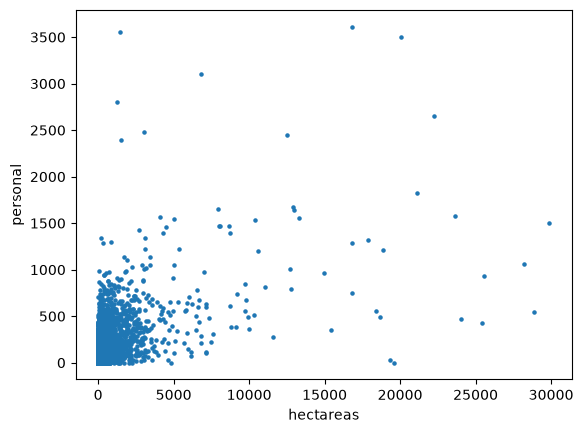

In [64]:
incendios.plot(kind = "scatter", x = "hectareas", y = "personal", s = 5)

### Se puede observar que aunque aumenten las hectareas, pocas veces hay más de 2000 personas luchando contra los incendios.

### A continuación, quiero crear una tabla que contenga sólo los grandes incendios, que son los que afectan a más de 500 hectáreas. Para comparar, he haré también una tabla de pequeños incendios. 

In [65]:
grandes_incendios = incendios[incendios["hectareas"] >= 500]

grandes_incendios.head(3)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,...,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas,impacto economico
54996,572.0,1983-03-25,1983,Marzo,3,42.066741,1.294414,Municipio más cercano,Cataluña,Lleida,...,Negligencias y accidentes,Supuesta,0,0,2700.0,74,8,3.0,97.0,100.0
55153,4720.0,1983-04-11,1983,Abril,4,41.007384,0.658895,Municipio más cercano,Cataluña,Tarragona,...,Causa desconocida,Supuesta,0,0,4800.0,347,4,35.0,649.0,684.0
55154,920.0,1983-04-11,1983,Abril,4,41.250402,1.516496,Municipio más cercano,Cataluña,Tarragona,...,Negligencias y accidentes,Supuesta,0,0,2760.0,206,0,5.0,149.0,154.0


In [66]:
pequeños_incendios = incendios[incendios["hectareas"] <= 500]

pequeños_incendios.head(3)

,hectareas,fecha,año,mes,numero mes,latitud,longitud,ubicación exacta,comunidad,provincia,...,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas,impacto economico
39711,20.0,1980-09-18,1980,Septiembre,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,...,Causa desconocida,Supuesta,0,0,420.0,12,0,0.0,1.0,1.0
54383,2.0,1983-01-04,1983,Enero,1,38.942962,-0.361213,Municipio más cercano,Comunidad Valenciana,Valencia,...,Reproducciones,Supuesta,0,0,180.0,13,0,0.0,0.0,0.0
54384,15.0,1983-01-05,1983,Enero,1,40.133460,-0.686263,Municipio más cercano,Aragón,Teruel,...,Negligencias y accidentes,Supuesta,0,0,360.0,78,0,1.0,0.0,1.0


### Con las nuevas tablas, voy a comprobar si hay algún cambio importante respecto a la tabla orginial.

In [67]:
print("En España han habido",len(grandes_incendios), "grandes incendios y", len(pequeños_incendios), "pequeños incendios")

En España han habido 1478 grandes incendios y 241046 pequeños incendios


<Axes: xlabel='año'>

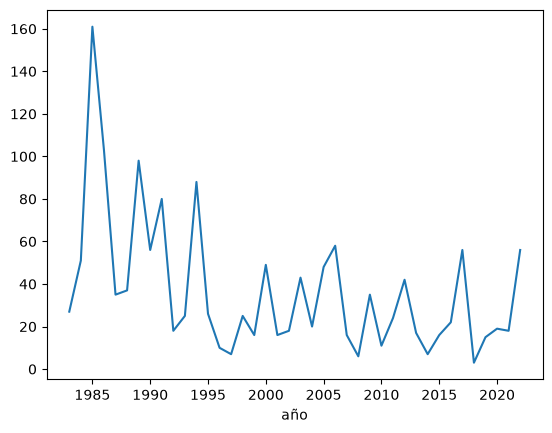

In [68]:
grandes_incendios["año"].value_counts().sort_index().plot(kind = "line")

<Axes: xlabel='año'>

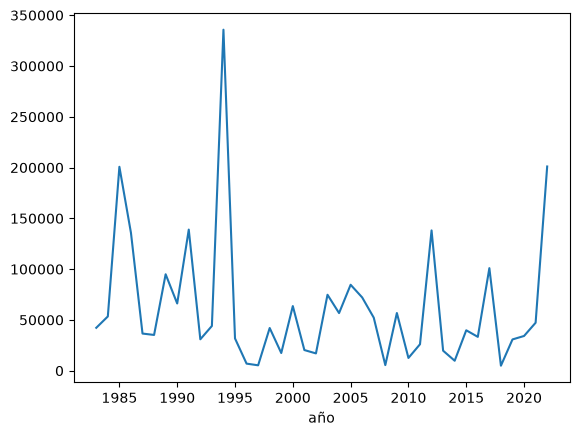

In [69]:
grandes_incendios.groupby("año")["hectareas"].sum().plot(kind = "line")

<Axes: ylabel='mes'>

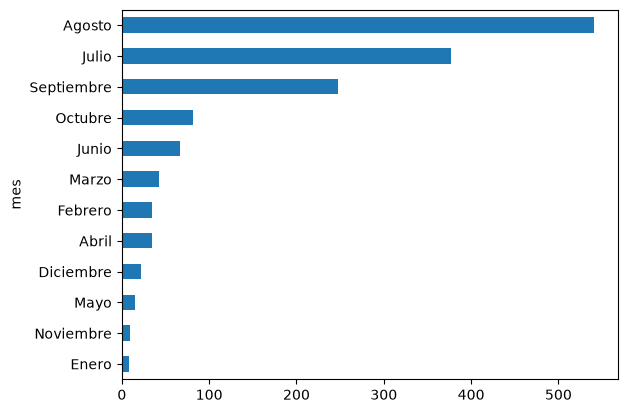

In [70]:
grandes_incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

<Axes: ylabel='mes'>

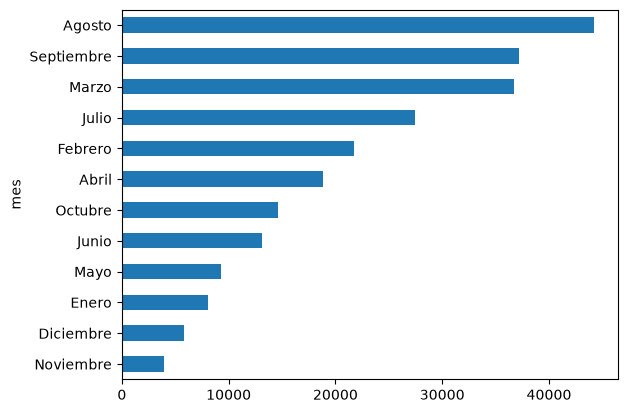

In [71]:
pequeños_incendios["mes"].value_counts(ascending = True).plot(kind = "barh")

In [72]:
round(grandes_incendios["causa"].value_counts() / len(grandes_incendios) * 100, 1)

causa
Causa desconocida            45.6
Reproducciones               22.5
Negligencias y accidentes    15.7
Causa Natural                 7.7
Intencionados                 7.3
Otras causas humanas          1.2
Name: count, dtype: float64

In [73]:
print("Hectáreas quemadas por grandes incendios:", grandes_incendios["hectareas"].sum().round(1), "Hectáreas quemadas por pequeños incendios:", pequeños_incendios["hectareas"].sum().round(1))

Hectáreas quemadas por grandes incendios: 2520397.8 Hectáreas quemadas por pequeños incendios: 3412605.5


In [74]:
print("Impacto economico medio de grandes incendios", grandes_incendios["impacto economico"].mean().round(1), "Impacto economico medio de pequeños incendios", pequeños_incendios["impacto economico"].mean().round(1))

Impacto economico medio de grandes incendios 882994.2 Impacto economico medio de pequeños incendios 6016.4


In [75]:
print("Impacto economico de grandes incendios", grandes_incendios["impacto economico"].sum().round(1), "Impacto economico de pequeños incendios", pequeños_incendios["impacto economico"].sum().round(1))

Impacto economico de grandes incendios 1305065355.0 Impacto economico de pequeños incendios 1450226049.0


In [76]:
print("Muertos en grandes incendios", grandes_incendios["muertos"].sum().round(1), "Muertos en pequeños incendios", pequeños_incendios["muertos"].sum().round(1))

Muertos en grandes incendios 95 Muertos en pequeños incendios 87


### Los 1478 grandes incendios casi igualan el impacto económico y en hectáreas de los 241.046 pequeños incendios, e incluso los superan en número de muertos. Los grandes incendios se concentran más en los meses de verano que el resto. Además, en cuanto a las causas, se reduce el porcentaje de causas desconocidas y aumentan otros, es decir, parece ser que conocemos más las causas en los grandes incendios.

### A continuación, voy a visualizar unos cuantos mapas

<Axes: title={'center': 'Incendios por comunidad'}, xlabel='longitud', ylabel='latitud'>

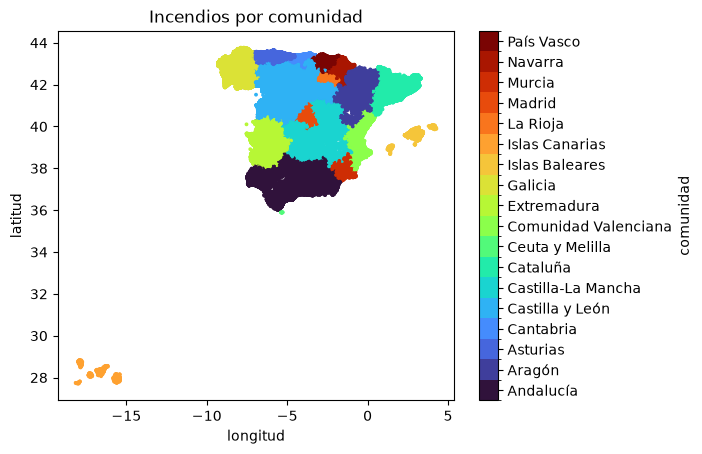

In [77]:
incendios["comunidad"] = incendios["comunidad"].astype("category") 
incendios.plot(kind="scatter", x="longitud", y="latitud", s=3, c="comunidad", colormap="turbo", title="Incendios por comunidad")

<Axes: title={'center': 'Incendios por provincia'}, xlabel='longitud', ylabel='latitud'>

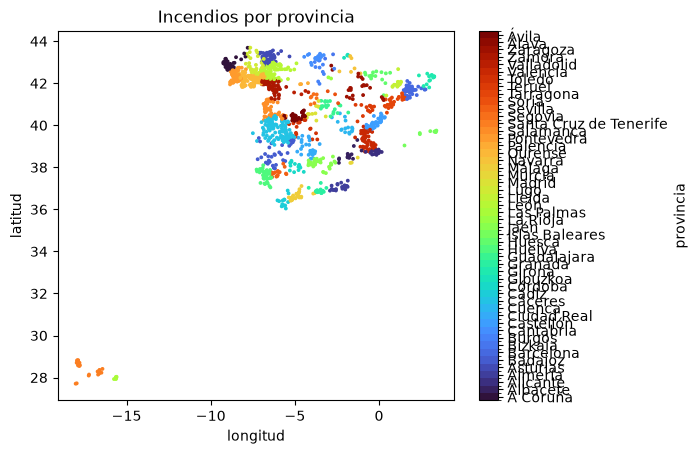

In [78]:
grandes_incendios["provincia"] = grandes_incendios["provincia"].astype("category") 
grandes_incendios.plot(kind="scatter", x="longitud", y="latitud", s=3, c="provincia", colormap="turbo", title="Incendios por provincia")

## 9. ¿Que he aprendido?

### Los grandes incendios, siendo muchos menos, tienen casi tanto impacto cómo los pequeños. 1478 grandes incendios (mayores de 500 hectáreas) han afectado a 2520397 hectáreas, han tenido un impacto económico de 1305065355 euros y han dejado un total de 95 muertos. Por otra parte los 241046 incendios pequeños han afectado a 3412605 hectareas, han tenido un coste de 1450226049 euros y han dejado un total de 87 muertos.

### Los meses más peligrosos son Agosto con un total de 1633105 hectareas quemadas, Julio con 1396002 hectareas quemadas y Septiembre con 880841 hectareas quemadas. 

### Las comunidades más afectadas son Galicia con el 34.1% de los incendios, Castilla y León con el 16.4% y Asturias con el 12.7%. La provincia con la media de hectáreas quemadas por incendio más alta es Santa Cruz de Tenerife con 160.9

### Hay menos incendios ahora que en el siglo pasado, y también son menos graves. Sin embargo, en la gráfica se puede apreciar un ligero aumento en los últimos años, siendo 2022 el peor año de este siglo con 242436 hectáreas quemadas.




In [79]:
incendios.to_csv("datos/incendios_limpios.csv", index=False)

In [80]:
grandes_incendios.to_csv("datos/grandes_limpios.csv", index=False)